In [6]:
import pandas as pd
import matplotlib.pyplot as plt
from wordcloud import WordCloud
import seaborn as sns

In [11]:
fichier_data = "../data/raw/dereev_synthetic_data_augmented.xlsx"

df = pd.read_excel(fichier_data)

colonne_notes = "cn_notes"
colonne_reev = 'reev_expert'
df[colonne_notes] = df[colonne_notes].astype(str)

print(f"{len(df)} notes ont été trouvées.")

749 notes ont été trouvées.


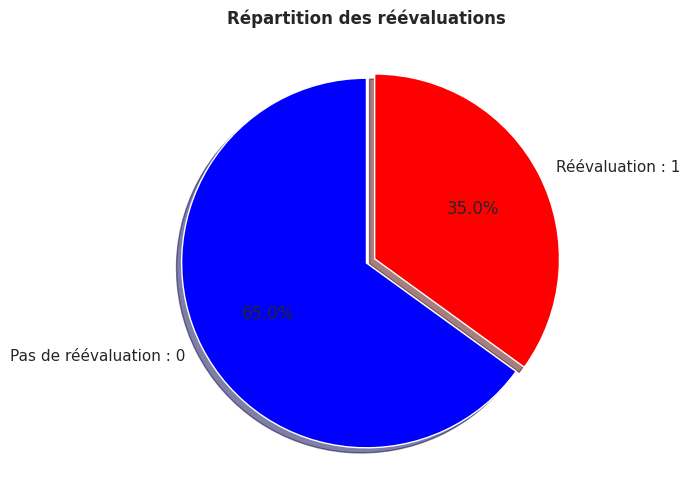

In [17]:
### PIE CHART RÉPARTITION DES CLASSES

plt.figure(figsize=(8,6))
repartition = df[colonne_reev].value_counts()
plt.pie(repartition, labels=["Pas de réévaluation : 0", "Réévaluation : 1"],
        autopct='%1.1f%%', startangle=90, explode=(0, 0.05), shadow=True, colors=["blue", 'red'])

plt.title("Répartition des réévaluations", fontweight='bold')
plt.show()

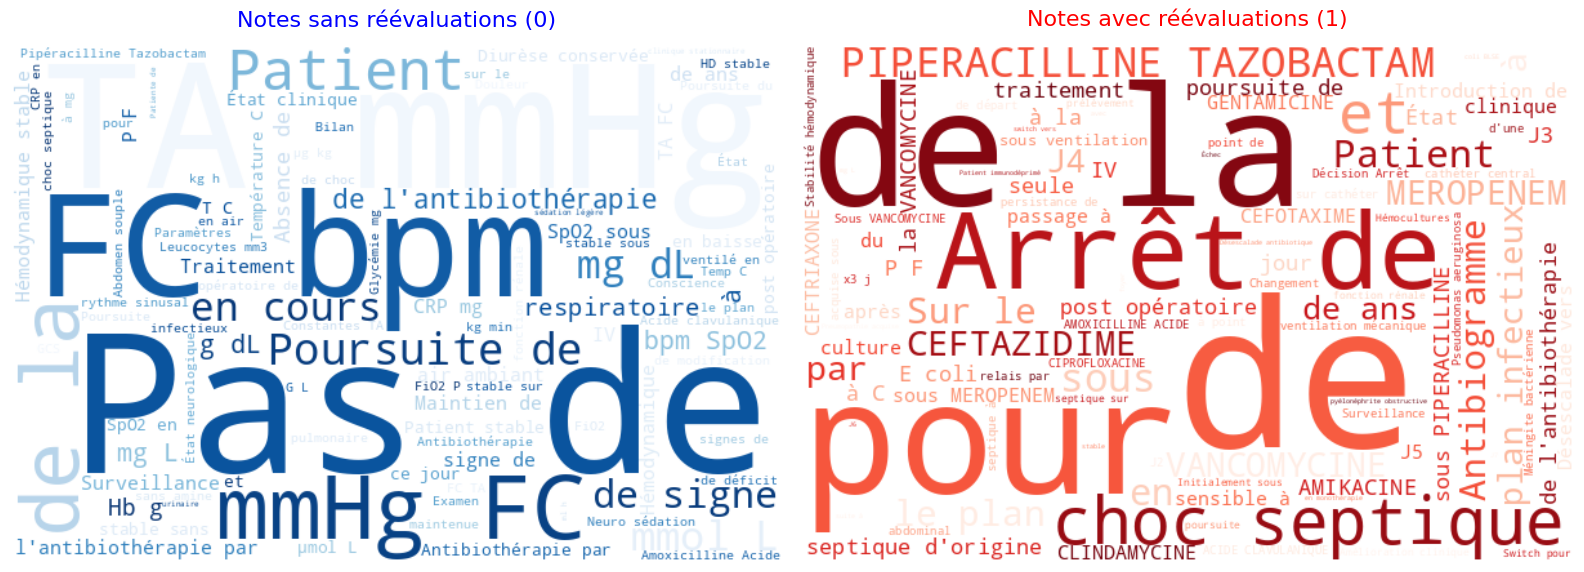

In [15]:
### WORDCLOUD 

texte_0 = " ".join(df[df[colonne_reev] == 0][colonne_notes])
texte_1 = " ".join(df[df[colonne_reev] == 1][colonne_notes])

wc_0 = WordCloud(width=600, height=400, background_color='white', colormap='Blues', max_words=100).generate(texte_0)
wc_1 = WordCloud(width=600, height=400, background_color='white', colormap='Reds', max_words=100).generate(texte_1)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].imshow(wc_0, interpolation='bilinear')
axes[0].axis('off')
axes[0].set_title("Notes sans réévaluations (0)", fontsize=16, color="blue", pad=15)

axes[1].imshow(wc_1, interpolation='bilinear')
axes[1].axis('off')
axes[1].set_title("Notes avec réévaluations (1)", fontsize=16, color='red', pad=15)

plt.tight_layout()
plt.show()

Moyenne      : 38.90787716955941 mots
Médiane      : 34.0 mots
Maximum      : 156 mots
Minimum      : 6 mots
90e Centile  : 56.0 mots


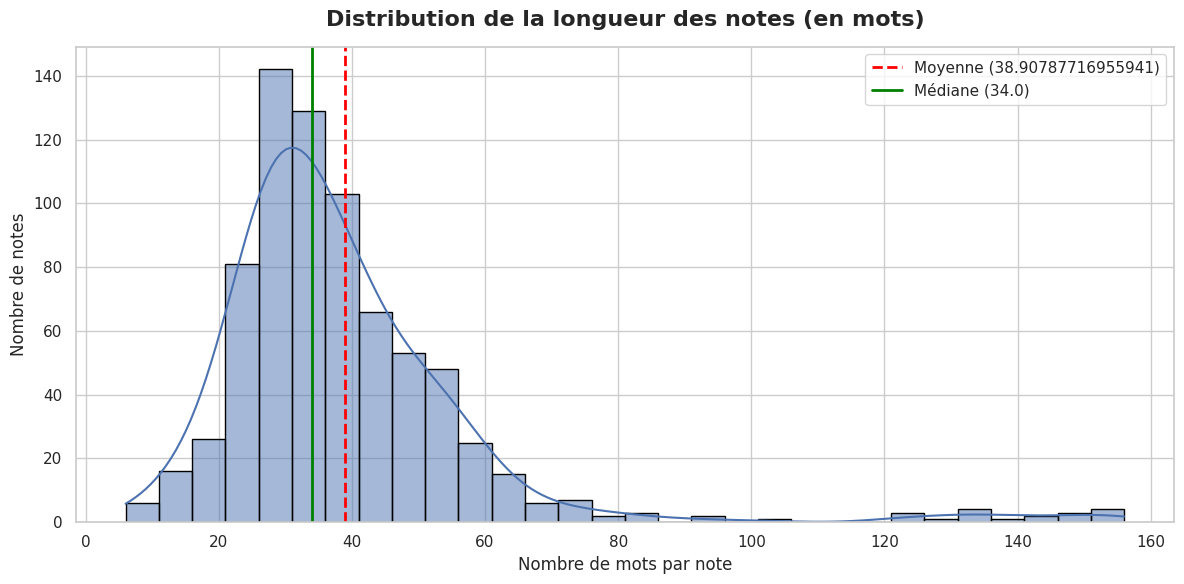

In [16]:
df['longueur_mots'] = df[colonne_notes].apply(lambda x: len(x.split()))
print(f"Moyenne      : {df['longueur_mots'].mean()} mots")
print(f"Médiane      : {df['longueur_mots'].median()} mots")
print(f"Maximum      : {df['longueur_mots'].max()} mots")
print(f"Minimum      : {df['longueur_mots'].min()} mots")
print(f"90e Centile  : {df['longueur_mots'].quantile(0.90)} mots") # 90% des notes sont en dessous

sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 6))

ax = sns.histplot(data=df, x='longueur_mots', bins=30, kde=True, color='#4C72B0', edgecolor='black')

plt.axvline(df['longueur_mots'].mean(), color='red', linestyle='--', linewidth=2, label=f"Moyenne ({df['longueur_mots'].mean()})")
plt.axvline(df['longueur_mots'].median(), color='green', linestyle='-', linewidth=2, label=f"Médiane ({df['longueur_mots'].median()})")

plt.title("Distribution de la longueur des notes (en mots)", fontsize=16, pad=15, fontweight='bold')
plt.xlabel("Nombre de mots par note", fontsize=12)
plt.ylabel("Nombre de notes", fontsize=12)
plt.legend(fontsize=11)

plt.tight_layout()
plt.show()
